# Lab 1 — Supervised learning on tabular data

**Machine Learning · M.EIC001**

In this first hands-on session you will walk through the full life-cycle of a (small) supervised learning problem on a single table of data:

1. **Get the data** — load a public dataset into Python.
2. **DataFrames** — inspect, select and filter observations with `pandas`.
3. **Exploratory data analysis (EDA)** — plots and simple arithmetic over columns.
4. **Feature inspection** — distributions, correlations, missing values, and the choice of a **target**.
5. **Class imbalance** — how are the target classes distributed?
6. **Train / test split** — a sound protocol for measuring generalisation.
7. **Baselines and models** — a naive baseline first, then a few standard classifiers.

### Supervised learning in one paragraph
We are given $n$ observations $\{(\mathbf{x}_i, y_i)\}_{i=1}^n$, where $\mathbf{x}_i \in \mathcal{X}$ is a vector of **features** (the columns of a table) and $y_i$ is a **target** (or *label*). We want to learn a function $f: \mathcal{X} \to \mathcal{Y}$ such that $f(\mathbf{x})$ is a good prediction of $y$ **for new, unseen observations** drawn from the same distribution. When $\mathcal{Y}$ is a finite set of categories we have a **classification** problem; when $\mathcal{Y} \subseteq \mathbb{R}$, a **regression** problem.

The key word is *unseen*: doing well on the data we trained on is easy; doing well on new data is the whole point.

### How to use this notebook
* Cells marked **Exercise** contain a `# YOUR CODE HERE` stub. Complete them in order — later cells depend on earlier ones.
* Cells marked **Question** ask for a short written answer (2–4 sentences). Write it in the markdown cell right below.
* Everything else is given code: run it, read it, and make sure you understand it.

## 0. Setup
The notebook needs `numpy`, `pandas`, `matplotlib`, `seaborn` and `scikit-learn` (≥ 1.2).

In [38]:
%pip install numpy pandas matplotlib seaborn scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

RANDOM_STATE = 42                     # fix every source of randomness -> reproducible results
SURV_PALETTE = {0: "#C44E52", 1: "#4C72B0"}   # consistent colours for the target: 0 = died, 1 = survived

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
pandas 3.0.0 | scikit-learn 1.9.1


## 1. The data: Titanic passengers

We use the **Titanic** dataset (1309 passengers of the RMS Titanic, 1912), published on [OpenML](https://www.openml.org/d/40945) (dataset id **40945**). It is small, but it has everything a real tabular dataset has: numerical and categorical columns, free text, missing values, skewed distributions — and even a couple of traps.

| column | description |
|---|---|
| `pclass` | ticket class (1 = 1st, 2 = 2nd, 3 = 3rd) |
| `survived` | 1 if the passenger survived, 0 otherwise |
| `name` | passenger name (includes a title: Mr., Mrs., Miss., …) |
| `sex` | female / male |
| `age` | age in years (fractional for infants) |
| `sibsp` | number of siblings / spouses aboard |
| `parch` | number of parents / children aboard |
| `ticket` | ticket number |
| `fare` | ticket price (British pounds) |
| `cabin` | cabin number |
| `embarked` | port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton) |
| `boat` | lifeboat identifier (if the passenger got into one) |
| `body` | body identification number (if the body was recovered) |
| `home.dest` | home / destination |

We download it with `sklearn.datasets.fetch_openml` and keep a local CSV copy, so the notebook also works offline after the first run.

In [39]:
from pathlib import Path
from sklearn.datasets import fetch_openml

DATA_PATH = Path("data") / "titanic_openml_40945.csv"

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    titanic = fetch_openml(data_id=40945, as_frame=True, parser="auto")
    df = titanic.frame
    DATA_PATH.parent.mkdir(exist_ok=True)
    df.to_csv(DATA_PATH, index=False)

# make the column types explicit (and identical whether we read from OpenML or from the CSV)
df["survived"] = df["survived"].astype(int)
df["sex"] = df["sex"].astype("category")
df["embarked"] = df["embarked"].astype("category")

print(df.shape)

(1309, 14)


## 2. DataFrames: inspecting, selecting and filtering

A `pandas.DataFrame` is a 2-D table with **labelled** rows (the *index*) and **labelled, typed** columns. Each column is a `pandas.Series` — a 1-D array with an index. In supervised-learning vocabulary: **rows are observations, columns are variables** (features or target).

### 2.1 First look

In [40]:
df.head()          # first 5 rows; try also df.tail(3) and df.sample(5, random_state=0)

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [41]:
df.info()          # column names, non-null counts and dtypes

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   pclass     1309 non-null   int64   
 1   survived   1309 non-null   int64   
 2   name       1309 non-null   str     
 3   sex        1309 non-null   category
 4   age        1046 non-null   float64 
 5   sibsp      1309 non-null   int64   
 6   parch      1309 non-null   int64   
 7   ticket     1309 non-null   str     
 8   fare       1308 non-null   float64 
 9   cabin      295 non-null    str     
 10  embarked   1307 non-null   category
 11  boat       486 non-null    str     
 12  body       121 non-null    float64 
 13  home.dest  745 non-null    str     
dtypes: category(2), float64(3), int64(4), str(5)
memory usage: 125.4 KB


In [42]:
df.describe()                     # summary statistics of the numerical columns

,pclass,survived,age,sibsp,parch,fare,body
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200,328.000000


In [43]:
df.describe(exclude="number")     # ... and of the non-numerical ones

,name,sex,ticket,cabin,embarked,boat,home.dest
count,1309,1309,1309,295,1307,486,745
unique,1307,2,929,186,3,27,369
top,"Connolly, Miss. Kate",male,CA. 2343,C23 C25 C27,S,13,"New York, NY"
freq,2,843,11,6,914,39,64


### 2.2 Selecting columns and rows
* `df["age"]` → one column (a `Series`); `df[["name", "age"]]` → several columns (a `DataFrame`).
* `df.loc[rows, cols]` selects by **label**; `df.iloc[rows, cols]` selects by **integer position**.
* A **boolean mask** (a Series of `True`/`False`) filters rows: `df[df["age"] < 10]`. Combine conditions with `&` (and), `|` (or), `~` (not) — and **always wrap each condition in parentheses**.
* `df.query("age < 10 and sex == 'female'")` is an alternative, often more readable syntax.

In [44]:
print(type(df["age"]), type(df[["name", "age"]]))

df.loc[10:14, ["name", "sex", "age", "survived"]]        # label-based: rows 10..14 INCLUSIVE

<class 'pandas.Series'> <class 'pandas.DataFrame'>


,name,sex,age,survived
10,"Astor, Col. John Jacob",male,47.0,0
11,"Astor, Mrs. John Jacob (Madeleine Talmadge Force)",female,18.0,1
12,"Aubart, Mme. Leontine Pauline",female,24.0,1
13,"Barber, Miss. Ellen 'Nellie'",female,26.0,1
14,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,1


In [45]:
df.iloc[:3, :4]                                          # position-based: first 3 rows, first 4 columns (end EXCLUSIVE)

,pclass,survived,name,sex
0,1,1,"Allen, Miss. Elisabeth Walton",female
1,1,1,"Allison, Master. Hudson Trevor",male
2,1,0,"Allison, Miss. Helen Loraine",female


In [46]:
children_3rd = df[(df["age"] < 10) & (df["pclass"] == 3)]
print(len(children_3rd), "children under 10 travelling in 3rd class")

df.query("pclass == 1 and sex == 'male' and age > 60")[["name", "age", "fare", "survived"]]

56 children under 10 travelling in 3rd class


,name,age,fare,survived
9,"Artagaveytia, Mr. Ramon",71.0,49.5042,0
14,"Barkworth, Mr. Algernon Henry Wilson",80.0,30.0000,1
81,"Crosby, Capt. Edward Gifford",70.0,71.0000,0
115,"Fortune, Mr. Mark",64.0,263.0000,0
135,"Goldschmidt, Mr. George B",71.0,34.6542,0
205,"Millet, Mr. Francis Davis",65.0,26.5500,0
217,"Nicholson, Mr. Arthur Ernest",64.0,26.0000,0
221,"Ostby, Mr. Engelhart Cornelius",65.0,61.9792,0
252,"Ryerson, Mr. Arthur Larned",61.0,262.3750,0
279,"Stead, Mr. William Thomas",62.0,26.5500,0


In [47]:
# sorting, counting and grouping
display(df.sort_values("fare", ascending=False).head(3)[["name", "pclass", "fare"]])
display(df["embarked"].value_counts(dropna=False))
df.groupby("pclass")[["age", "fare"]].mean()

,name,pclass,fare
302,"Ward, Miss. Anna",1,512.3292
49,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292
50,"Cardeza, Mrs. James Warburton Martinez (Charlo...",1,512.3292


embarked
S      914
C      270
Q      123
NaN      2
Name: count, dtype: int64

,age,fare
pclass,,
1,39.159918,87.508992
2,29.506705,21.179196
3,24.816367,13.302889


**Exercise 2.1** — How many passengers travelled in each class? Show both the **counts** and the **proportions** (hint: `value_counts(normalize=True)`), sorted by class.

In [48]:
# YOUR CODE HERE
display(df["pclass"].value_counts(dropna=False), df["pclass"].value_counts(normalize=True))

pclass
3    709
1    323
2    277
Name: count, dtype: int64

pclass
3    0.541635
1    0.246753
2    0.211612
Name: proportion, dtype: float64

**Exercise 2.2** — Select the passengers who **embarked at Cherbourg**, travelled in **1st class** and were **older than 50**. Show only `name`, `age`, `fare` and `survived`, sorted by `fare` (descending). How many are there, and how many survived?

In [49]:
# YOUR CODE HERE
mask = df[(df["age"] > 50) & (df["embarked"] == "C") & (df["pclass"] == 1)].sort_values("fare", ascending=False)[["name", "age", "fare", "survived"]]

display(mask)

print("\n", len(mask), "people found.")
print("\n", len(mask[(df["survived"] == 1)]), "people survived.\n")

,name,age,fare,survived
50,"Cardeza, Mrs. James Warburton Martinez (Charlo...",58.0,512.3292,1
252,"Ryerson, Mr. Arthur Larned",61.0,262.3750,0
192,"Lurette, Miss. Elise",58.0,146.5208,1
276,"Spencer, Mr. William Augustus",57.0,146.5208,0
308,"White, Mrs. John Stuart (Ella Holmes)",55.0,135.6333,1
215,"Newell, Mr. Arthur Webster",58.0,113.2750,0
233,"Potter, Mrs. Thomas Jr (Lily Alexenia Wilson)",56.0,83.1583,1
78,"Compton, Mrs. Alexander Taylor (Mary Eliza Ing...",64.0,83.1583,1
123,"Frolicher-Stehli, Mr. Maxmillian",60.0,79.2000,1
104,"Eustis, Miss. Elizabeth Mussey",54.0,78.2667,1



 27 people found.

 16 people survived.



C:\Users\jules\AppData\Local\Temp\ipykernel_26348\4110691835.py:7: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  print("\n", len(mask[(df["survived"] == 1)]), "people survived.\n")


**Exercise 2.3** — For each ticket class, compute the **minimum, median, mean and maximum fare** in a single table (hint: `groupby(...).agg([...])`). Which passenger(s) paid the highest fare? Is anything suspicious in the minimum fares?

In [50]:
# YOUR CODE HERE
df.groupby("pclass")[["fare"]].agg(["min", "median", "mean", "max"])

fare                              
        min   median       mean       max
pclass                                   
1       0.0  60.0000  87.508992  512.3292
2       0.0  15.0458  21.179196   73.5000
3       0.0   8.0500  13.302889   69.5500

> ✍️ **Your answer:** *Those who paid the highest fare are the Class 1 passengers, but the minimum fares are all equal to 0.0, very suspicious dataset...*

**Exercise 2.4** — Missing values. Build a table with the **number** and the **percentage** of missing values per column, sorted from most to least missing (hint: `isna()`).

In [51]:
# YOUR CODE HERE
number_isna = df.isna().sum().sort_values(ascending=False)
percentage_isna = (number_isna / len(df)) * 100

final_df = pd.DataFrame({
    "missing val" : number_isna,
    "percentage" : percentage_isna
})

display(final_df)

,missing val,percentage
body,1188,90.756303
cabin,1014,77.463713
boat,823,62.872422
home.dest,564,43.086325
age,263,20.091673
embarked,2,0.152788
fare,1,0.076394
sibsp,0,0.000000
name,0,0.000000
survived,0,0.000000


**Exercise 2.5** — The `name` column hides a useful piece of information: the **title** (`"Braund, Mr. Owen Harris"` → `Mr`). Create a new column `title` using the string accessor `df["name"].str.extract(...)` with a regular expression, and count the passengers per title.

In [52]:
# YOUR CODE HERE
df["title"] = df["name"].str.extract(r"([A-Za-z]+\.)")

print(df["title"].value_counts())

title
Mr.          757
Miss.        260
Mrs.         197
Master.       61
Dr.            8
Rev.           8
Col.           4
Major.         2
Mlle.          2
Ms.            2
Mme.           1
Capt.          1
Lady.          1
Sir.           1
Dona.          1
Jonkheer.      1
Countess.      1
Don.           1
Name: count, dtype: int64


## 3. Exploratory data analysis (EDA)

EDA is about **looking at the data before modelling it**: checking ranges and units, spotting errors and outliers, understanding distributions, and forming hypotheses. Two tools: plots, and new columns computed from existing ones.

### 3.1 Distributions of single variables

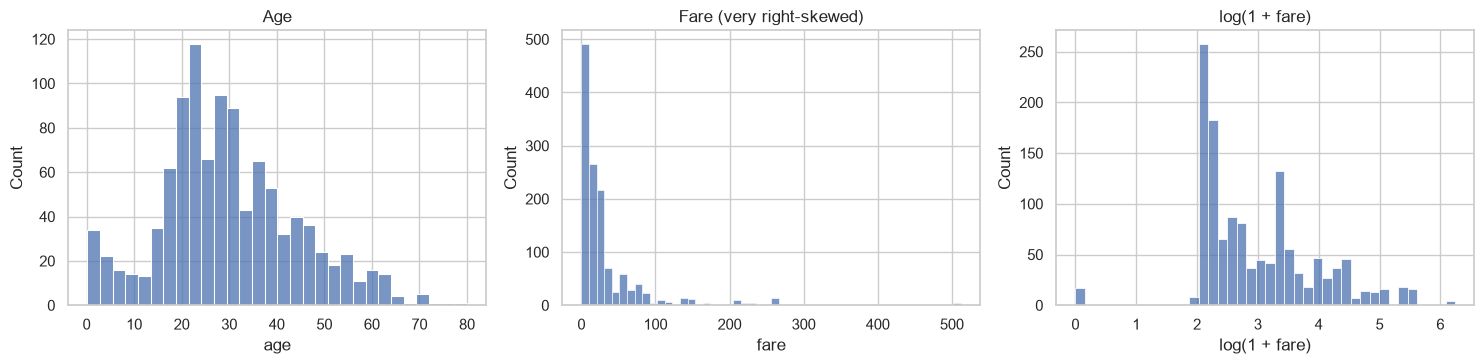

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

sns.histplot(data=df, x="age", bins=30, ax=axes[0])
axes[0].set_title("Age")

sns.histplot(data=df, x="fare", bins=50, ax=axes[1])
axes[1].set_title("Fare (very right-skewed)")

sns.histplot(x=np.log1p(df["fare"]), bins=40, ax=axes[2])
axes[2].set(title="log(1 + fare)", xlabel="log(1 + fare)")

plt.tight_layout()

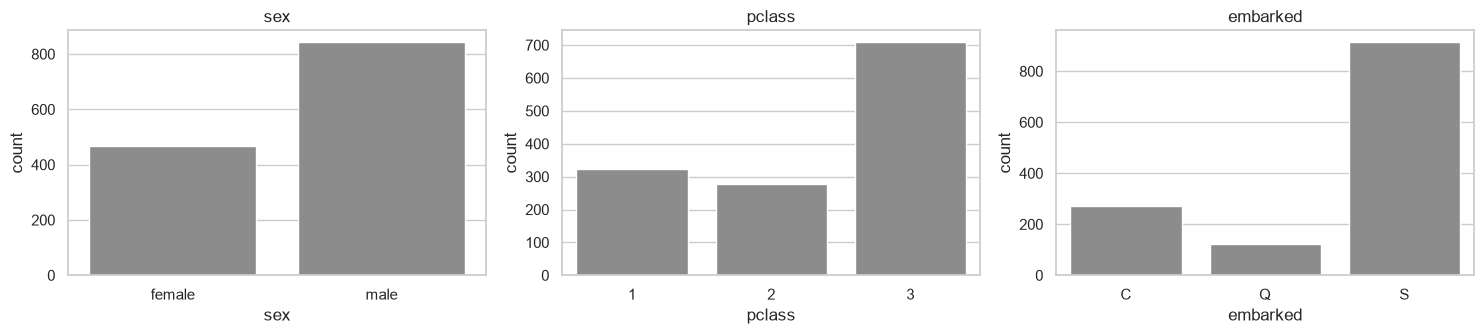

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["sex", "pclass", "embarked"]):
    sns.countplot(data=df, x=col, ax=ax, color="#8C8C8C")
    ax.set_title(col)
plt.tight_layout()

### 3.2 Arithmetic over columns
Columns can be combined with ordinary arithmetic; the operation is applied element-wise (*vectorised*) across all rows. For instance, the size of the family travelling with each passenger:

In [55]:
df["family_size"] = df["sibsp"] + df["parch"] + 1        # +1 for the passenger themself
df["family_size"].describe()

count    1309.000000
mean        1.883881
std         1.583639
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        11.000000
Name: family_size, dtype: float64

`fare` is the price of a **ticket**, and several passengers can share one ticket. A fairer comparison is the fare **per person** — we can count how many passengers share each ticket with `groupby(...).transform("count")`, which returns one value per row:

In [56]:
df["ticket_group_size"] = df.groupby("ticket")["ticket"].transform("count")
df["fare_per_person"] = df["fare"] / df["ticket_group_size"]
df[["name", "ticket", "fare", "ticket_group_size", "fare_per_person"]].sort_values("ticket").head(6)

,name,ticket,fare,ticket_group_size,fare_per_person
67,"Cherry, Miss. Gladys",110152,86.50,3,28.833333
245,"Rothes, the Countess. of (Lucy Noel Martha Dye...",110152,86.50,3,28.833333
195,"Maioni, Miss. Roberta",110152,86.50,3,28.833333
289,"Taussig, Miss. Ruth",110413,79.65,3,26.550000
291,"Taussig, Mrs. Emil (Tillie Mandelbaum)",110413,79.65,3,26.550000
290,"Taussig, Mr. Emil",110413,79.65,3,26.550000


### 3.3 Relationships between variables
Box plots summarise a numerical variable per category (median, quartiles, whiskers at 1.5·IQR, outliers as dots); scatter plots show two numerical variables against each other.

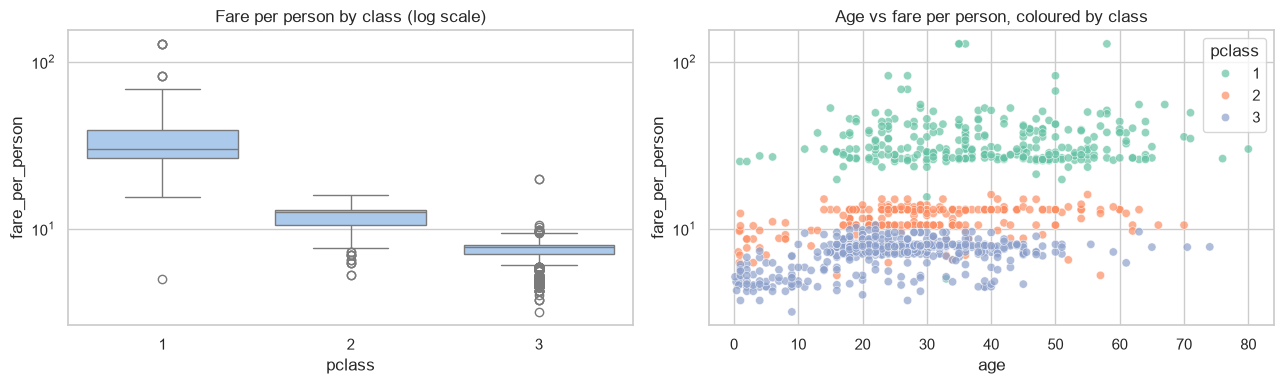

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
paid = df[df["fare_per_person"] > 0]          # log scale: leave out the (few) zero fares
sns.boxplot(data=paid, x="pclass", y="fare_per_person", ax=axes[0], color="#A1C9F4", log_scale=True)
axes[0].set_title("Fare per person by class (log scale)")

sns.scatterplot(data=paid, x="age", y="fare_per_person", hue="pclass", palette="Set2", alpha=0.7, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Age vs fare per person, coloured by class")
plt.tight_layout()

**Exercise 3.1** — Draw a **box plot of `age` per `pclass`, split by `sex`** (hint: `hue=`). Which group is the oldest? Formulate one hypothesis that could explain it.

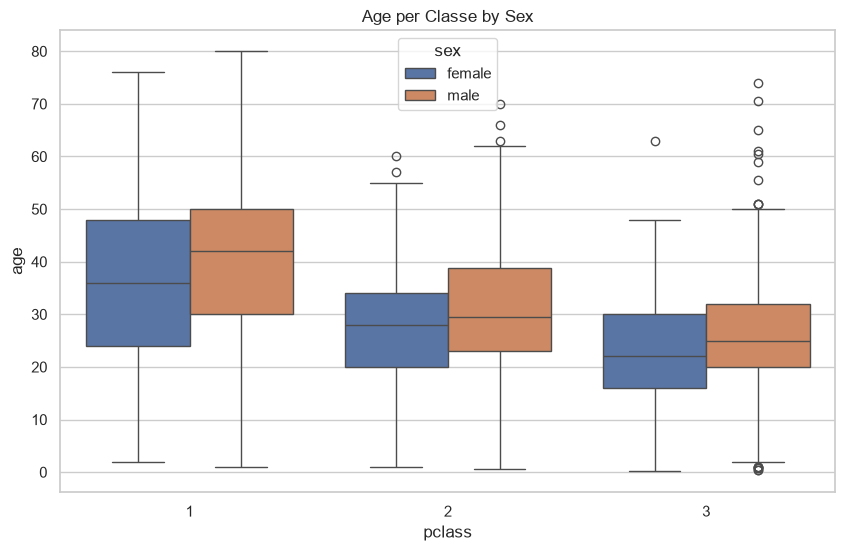

In [58]:
# YOUR CODE HERE
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

sns.boxplot(data=df, x="pclass", y="age", hue="sex", ax=ax)
ax.set_title("Age per Classe by Sex")

plt.show()

> ✍️ **Your answer:** *The oldest group is in the first class, because they have more money to afford a ticket (older = more time to gain money)*

**Exercise 3.2** — Use `pd.crosstab` to study **port of embarkation × class** in three ways, shown side by side as annotated heatmaps (`sns.heatmap(..., annot=True)`):
(a) raw **counts**; (b) normalised so that **each row sums to 1** (`normalize="index"`); (c) normalised so that **each column sums to 1** (`normalize="columns"`).

Then answer two questions that sound alike but are not:
1. *At which port were 1st-class passengers the majority of those who boarded?*
2. *At which port did most of the 1st-class passengers board?*

Which table answers each question?

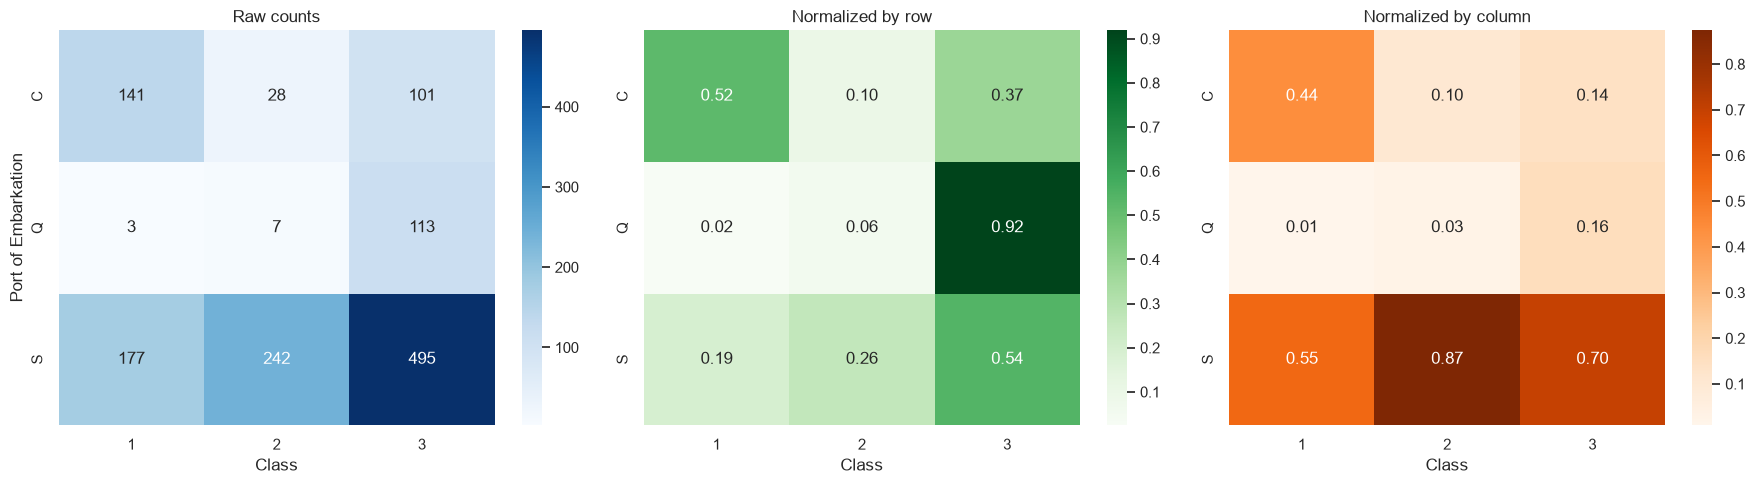

In [59]:
# YOUR CODE HERE
ct_raw = pd.crosstab(df['embarked'], df['pclass'])

ct_row = pd.crosstab(df['embarked'], df['pclass'], normalize='index')

ct_col = pd.crosstab(df['embarked'], df['pclass'], normalize='columns')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(ct_raw, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Raw counts')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Port of Embarkation')

sns.heatmap(ct_row, annot=True, fmt='.2f', cmap='Greens', ax=axes[1])
axes[1].set_title('Normalized by row')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('')

sns.heatmap(ct_col, annot=True, fmt='.2f', cmap='Oranges', ax=axes[2])
axes[2].set_title('Normalized by column')
axes[2].set_xlabel('Class')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

> ✍️ **Your answer:** *Cherbourg and Southampton.*

## 4. Feature inspection and choice of the target

### 4.1 What kind of columns do we have?
Before any modelling, classify each column — the type determines how it can be used:

| type | columns | notes |
|---|---|---|
| continuous numerical | `age`, `fare` (+ `fare_per_person`) | skewed (`fare`), missing values (`age`) |
| discrete numerical (counts) | `sibsp`, `parch` (+ `family_size`) | |
| ordinal categorical | `pclass` | ordered: 1st > 2nd > 3rd — can be kept as a number |
| nominal categorical | `sex`, `embarked` (+ `title`) | no order → must be encoded (e.g. one-hot) |
| identifiers / free text | `name`, `ticket`, `cabin`, `home.dest` | high cardinality; need feature engineering to be useful |
| **recorded after the event** | `boat`, `body` | ⚠️ see Exercise 4.3 |

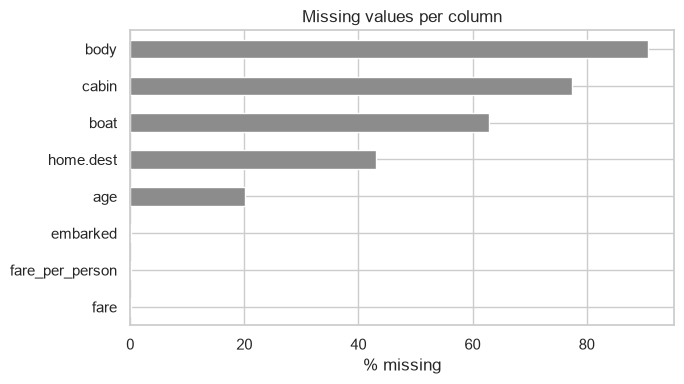

In [60]:
fig, ax = plt.subplots(figsize=(7, 4))
(100 * df.isna().mean()).loc[lambda s: s > 0].sort_values().plot.barh(ax=ax, color="#8C8C8C")
ax.set(xlabel="% missing", title="Missing values per column")
plt.tight_layout()

### 4.2 Correlations between numerical variables
The **Pearson** coefficient measures *linear* association; the **Spearman** coefficient (Pearson on ranks) measures *monotonic* association and is more robust to skewness and outliers — a better choice for `fare`.

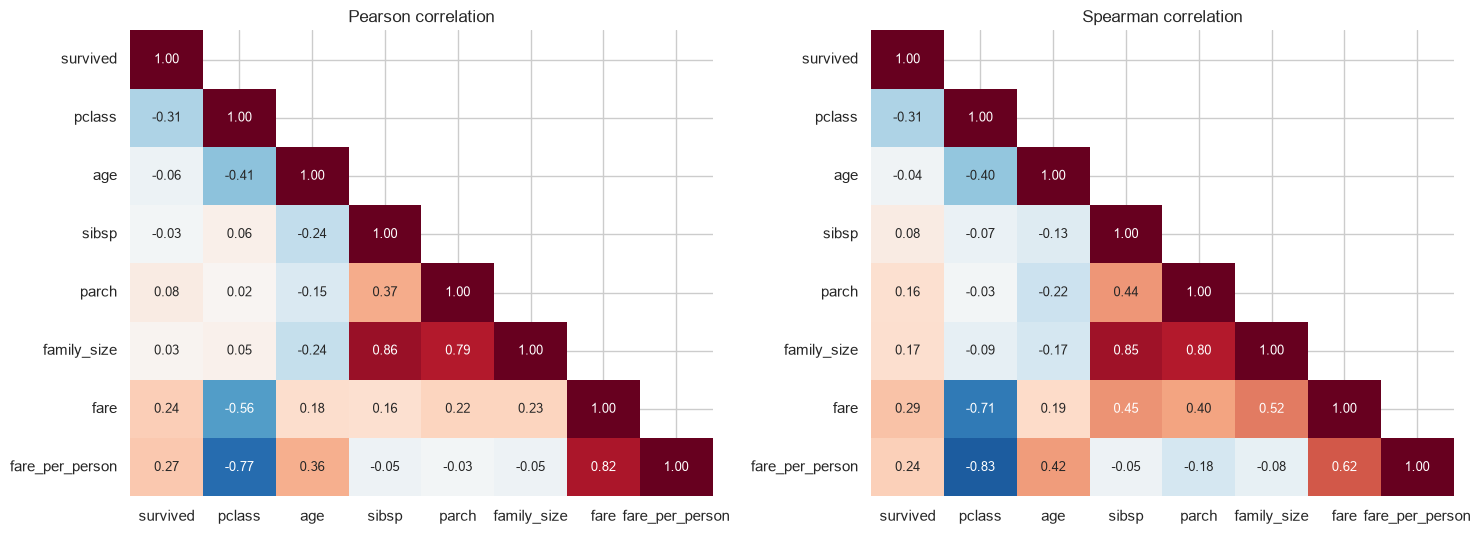

In [61]:
num_cols = ["survived", "pclass", "age", "sibsp", "parch", "family_size", "fare", "fare_per_person"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = df[num_cols].corr(method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)          # hide the redundant upper triangle
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                cbar=False, ax=ax, annot_kws={"size": 9})
    ax.set_title(f"{method.capitalize()} correlation")
plt.tight_layout()

### 4.3 Choosing a target
Several columns are **categorical** and could, in principle, be the target of a classifier: `survived` (2 classes), `pclass` (3), `sex` (2), `embarked` (3), `title` (many). The target should follow from a **question worth answering**. Here, the natural one is:

> *Given what was known about a passenger when they boarded, how likely were they to survive?*

So our target is **`survived`** — a **binary classification** problem. Note the phrase *"when they boarded"*: it tells us which columns are legitimate features.

**Question 4.1** — Pick one of the *other* categorical columns (e.g. `pclass` or `embarked`) and describe what a classifier predicting it from the remaining columns would mean. Would it be a useful model? Could it be useful as a way of **imputing** missing values?

> ✍️ **Your answer:** *If I choose pclass, it means that I'm trying to find the class of a passenger from thanks to his caracteristics. It would not be that useful because we already have pclass in the dataset. But as a way of imputing missing values yes, we could use the fare to find the pclass (strong correlation), same for embarked (with pclass and fare).*

**Exercise 4.2** — How does the survival rate depend on each feature? Draw bar plots of the **mean of `survived`** (= survival rate) per value of `sex`, `pclass`, `embarked` and `family_size` (hint: `sns.barplot(..., y="survived")` computes the mean and a 95% confidence interval). Then show the survival rate for the combination **`sex` × `pclass`** as a heatmap (hint: `pivot_table`).

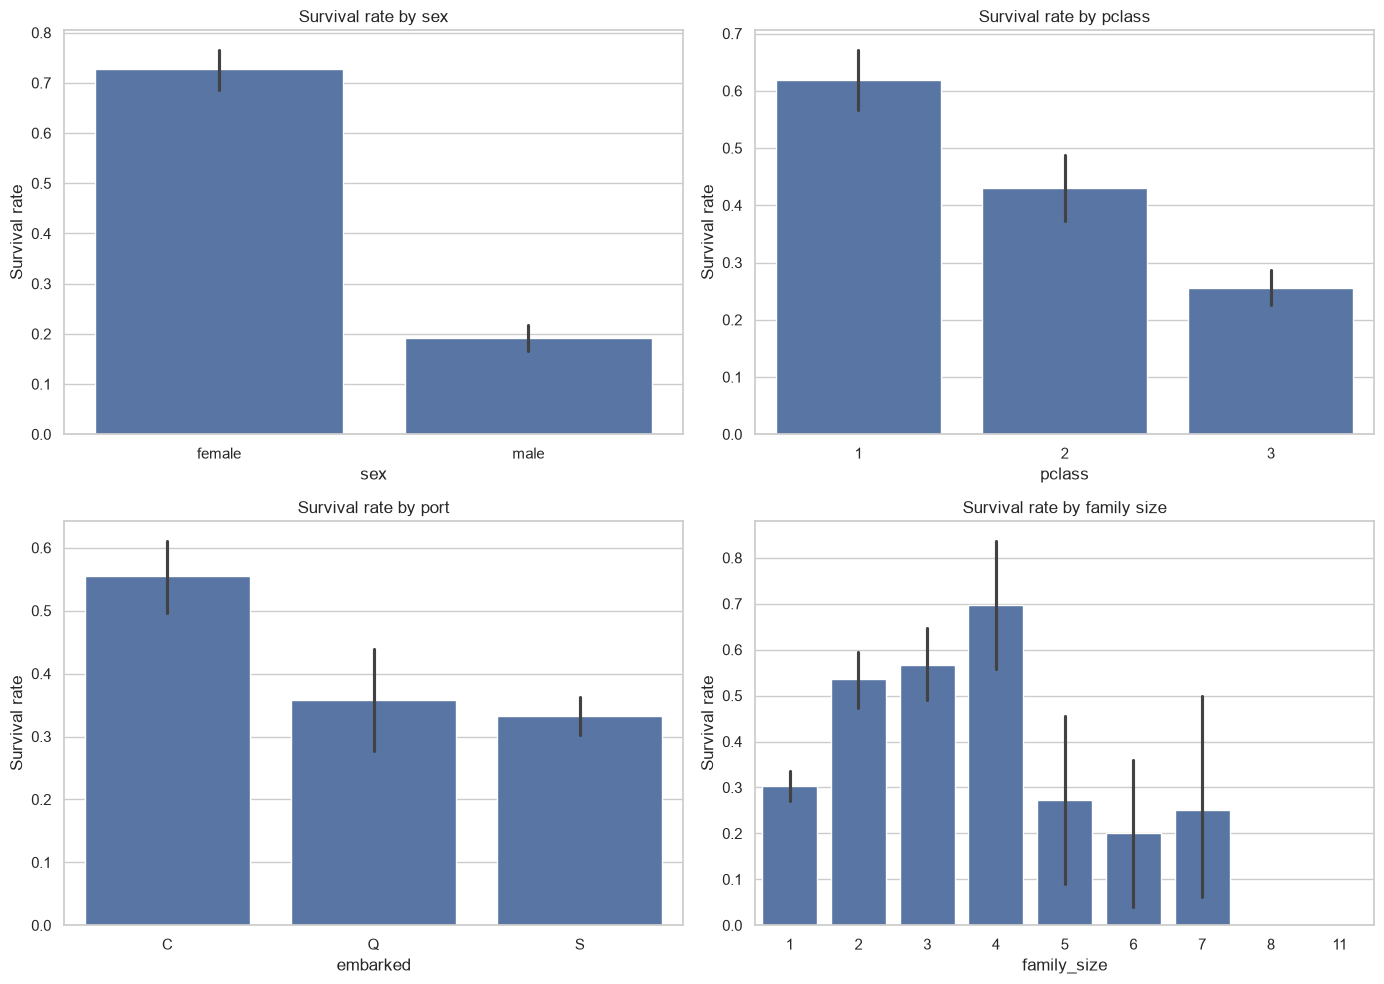

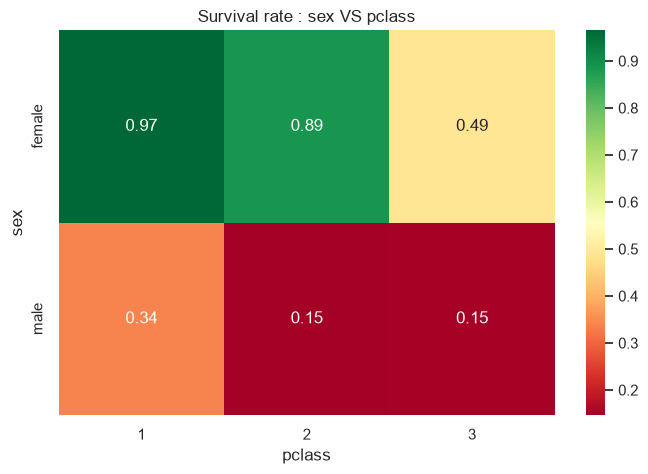

In [62]:
# YOUR CODE HERE
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.barplot(data=df, x='sex', y='survived', ax=axes[0, 0])
axes[0, 0].set_title('Survival rate by sex')
axes[0, 0].set_ylabel('Survival rate')

sns.barplot(data=df, x='pclass', y='survived', ax=axes[0, 1])
axes[0, 1].set_title('Survival rate by pclass')
axes[0, 1].set_ylabel('Survival rate')

sns.barplot(data=df, x='embarked', y='survived', ax=axes[1, 0])
axes[1, 0].set_title('Survival rate by port')
axes[1, 0].set_ylabel('Survival rate')

if 'family_size' not in df.columns:
    df['family_size'] = df['sibsp'] + df['parch'] + 1

sns.barplot(data=df, x='family_size', y='survived', ax=axes[1, 1])
axes[1, 1].set_title('Survival rate by family size')
axes[1, 1].set_ylabel('Survival rate')

plt.tight_layout()
plt.show()

pivot_sex_pclass = df.pivot_table(values='survived', index='sex', columns='pclass', aggfunc='mean')

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_sex_pclass, annot=True, fmt='.2f', cmap='RdYlGn')
plt.title('Survival rate : sex VS pclass')
plt.show()

> ✍️ **Your answer:** *The person with the highest survival rate would be a women in 1st class, in a family between 2 and 4 persons, embarked in Cherbourg.*

**Exercise 4.3 — a trap.** Compute the survival rate for passengers **with** and **without** a value in `boat`, and the same for `body` (hint: `df["boat"].notna()`). Should these columns be used as features? Why?

In [63]:
# YOUR CODE HERE
boat_survival = df.groupby(df['boat'].notna())['survived'].mean()
print("Survival rate based on 'boat':\n")
print(boat_survival)
print("-" * 30)

body_survival = df.groupby(df['body'].notna())['survived'].mean()
print("Survival rate based on 'body':\n")
print(body_survival)

Survival rate based on 'boat':

boat
False    0.027947
True     0.981481
Name: survived, dtype: float64
------------------------------
Survival rate based on 'body':

body
False    0.420875
True     0.000000
Name: survived, dtype: float64


> ✍️ **Your answer:** *These columns shouldn't be used in the model because it gives real infos on the survival state of each person (it's cheating, not predicting).*

**Exercise 4.4** — Compare the distributions of `age` and `fare_per_person` for survivors vs non-survivors (hint: `sns.histplot(..., hue="survived", stat="density", common_norm=False)`; use a log scale for the fare). What do you conclude?

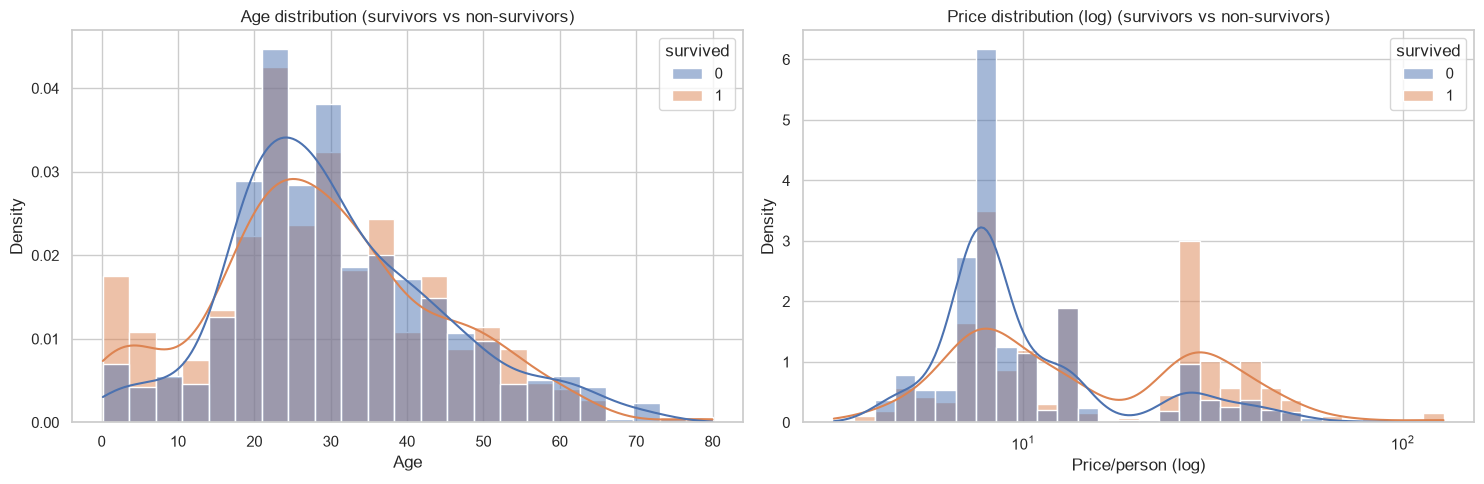

In [64]:
# YOUR CODE HERE
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

df_age_clean = df.dropna(subset=['age'])
sns.histplot(data=df_age_clean, x='age', hue='survived', stat='density', common_norm=False, kde=True, ax=axes[0])
axes[0].set_title('Age distribution (survivors vs non-survivors)')
axes[0].set_xlabel('Age')

if 'fare_per_person' not in df.columns:
    df['fare_per_person'] = df['fare']

df_fare_clean = df.dropna(subset=['fare_per_person'])
df_fare_clean = df_fare_clean[df_fare_clean['fare_per_person'] > 0]

sns.histplot(data=df_fare_clean, x='fare_per_person', hue='survived', stat='density', common_norm=False, kde=True, log_scale=True, ax=axes[1])
axes[1].set_title('Price distribution (log) (survivors vs non-survivors)')
axes[1].set_xlabel('Price/person (log)')

plt.tight_layout()
plt.show()

> ✍️ **Your answer:** *Young passengers and those who paid more had a higher survival rate (non-linear correlation).*

## 5. Class imbalance

A classification dataset is **imbalanced** when some classes are much more frequent than others. Imbalance matters because (i) a model can reach a high *accuracy* just by always predicting the majority class and (ii) random splits may leave few examples of the minority class in a subset.

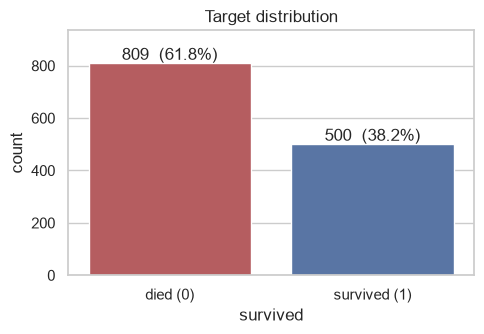

In [65]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="survived", hue="survived", palette=SURV_PALETTE, legend=False, ax=ax)
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{int(h)}  ({h / len(df):.1%})", (p.get_x() + p.get_width() / 2, h),
                    ha="center", va="bottom")
ax.set(xticks=[0, 1], xticklabels=["died (0)", "survived (1)"], title="Target distribution")
ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
plt.tight_layout()

**Exercise 5.1** — Compute the **imbalance ratio** (majority count / minority count). What accuracy would a "classifier" that always predicts *died* obtain on this dataset?

In [66]:
# YOUR CODE HERE
counts = df['survived'].value_counts()

majority_count = counts[0]
minority_count = counts[1]

imbalance_ratio = majority_count / minority_count

naive_accuracy = majority_count / len(df)

print(f"Imbalance ratio : {imbalance_ratio:.2f}")
print(f"Classifier accuracy (always predicts 'died') : {naive_accuracy:.2%}")

Imbalance ratio : 1.62
Classifier accuracy (always predicts 'died') : 61.80%


**Exercise 5.2** — The balance of the target can be very different inside **subgroups**. Draw a **100% stacked bar chart** of the target proportions per `pclass` and per `sex` (hint: `pd.crosstab(..., normalize="index").plot.bar(stacked=True)`).

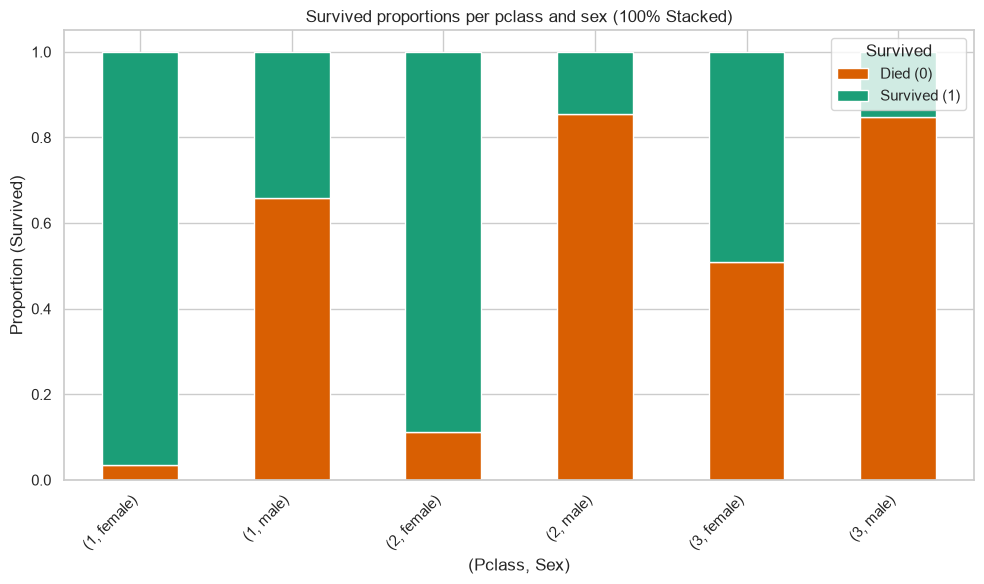

In [67]:
# YOUR CODE HERE
import matplotlib.pyplot as plt

target_by_subgroup = pd.crosstab(
    index=[df['pclass'], df['sex']],
    columns=df['survived'],
    normalize='index'
)

target_by_subgroup.plot.bar(stacked=True, figsize=(10, 6), color=['#d95f02', '#1b9e77'])

plt.title('Survived proportions per pclass and sex (100% Stacked)')
plt.xlabel('(Pclass, Sex)')
plt.ylabel('Proportion (Survived)')
plt.legend(title='Survived', labels=['Died (0)', 'Survived (1)'])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Question 5.3** — Is this dataset *severely* imbalanced? Give an example of a real-world problem where imbalance is far worse, and explain why accuracy would then be a misleading metric.

> ✍️ **Your answer:** *No. With a ratio of roughly 1.6:1 (61.8% vs. 38.2%), this is considered a mild to moderate class imbalance. Standard machine learning algorithms can generally handle this level of imbalance without needing aggressive resampling techniques (like SMOTE) or heavy class weighting, though it is still good practice to keep it in mind during model evaluation. Credit card fraud detection or network intrusion detection. In fraud detection, legitimate transactions vastly outnumber fraudulent ones. The imbalance ratio is often 1:100, 1:1,000, or even worse (e.g., less than 0.1% of transactions are fraud). Accuracy measures the overall percentage of correct predictions. In a dataset where 99.9% of transactions are legitimate, a "dumb" model that always predicts "Legitimate" will achieve 99.9% accuracy. However, it will completely fail to catch any fraud (0% recall for the minority class). Therefore, accuracy gives a false sense of high performance. For highly imbalanced problems, metrics like Precision, Recall, F1-score, or ROC-AUC are much more informative because they focus on the model's ability to correctly identify the minority class.*

## 6. Train / test split

To estimate how a model performs on **unseen** data, we hold out part of the data as a **test set**. The model (and *every* decision made while building it: preprocessing statistics, feature choices, hyper-parameters) must only use the **training set**. The test set is used once, at the end.

> ⚠️ Strictly speaking, the EDA above already looked at the whole dataset, which is a mild form of *data snooping*. In a real project, split **first** and explore only the training set. We did it this way here for teaching purposes.

We choose the features that are **known at boarding time** and require no heavy text processing:

In [68]:
from sklearn.model_selection import train_test_split

NUM_FEATURES = ["pclass", "age", "sibsp", "parch", "fare"]
CAT_FEATURES = ["sex", "embarked"]
FEATURES = NUM_FEATURES + CAT_FEATURES
TARGET = "survived"

X = df[FEATURES]
y = df[TARGET]
X.head()

,pclass,age,sibsp,parch,fare,sex,embarked
0,1,29.0000,0,0,211.3375,female,S
1,1,0.9167,1,2,151.5500,male,S
2,1,2.0000,1,2,151.5500,female,S
3,1,30.0000,1,2,151.5500,male,S
4,1,25.0000,1,2,151.5500,female,S


**Exercise 6.1** — Split `X, y` into **80% train / 20% test** with `train_test_split`, using `random_state=RANDOM_STATE` and **stratifying on the target**. Print the size of each set and the proportion of survivors in `y`, `y_train` and `y_test`.

In [69]:
# YOUR CODE HERE
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Size of X_train: {len(X_train)}")
print(f"Size of X_test:  {len(X_test)}")
print(f"Size of y_train: {len(y_train)}")
print(f"Size of y_test:  {len(y_test)}")
print("-" * 30)

print(f"Proportion of survivors in y (full dataset): {y.mean():.4f}")
print(f"Proportion of survivors in y_train:          {y_train.mean():.4f}")
print(f"Proportion of survivors in y_test:           {y_test.mean():.4f}")

Size of X_train: 1047
Size of X_test:  262
Size of y_train: 1047
Size of y_test:  262
------------------------------
Proportion of survivors in y (full dataset): 0.3820
Proportion of survivors in y_train:          0.3820
Proportion of survivors in y_test:           0.3817


Let us check visually that the two subsets look like samples of the same population — both for the target and for some features:

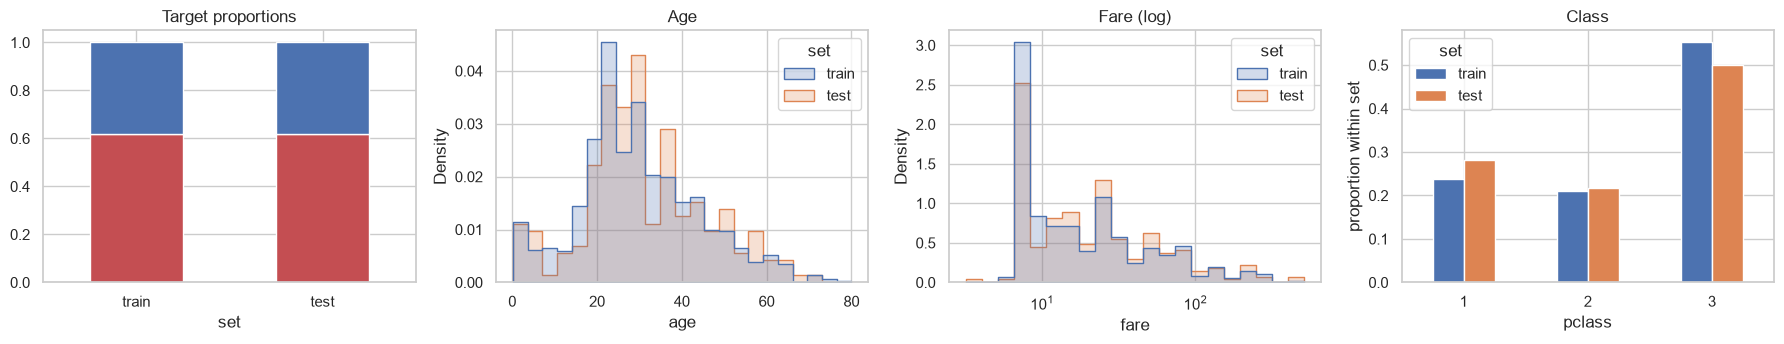

In [70]:
split = pd.concat([X_train.assign(survived=y_train, set="train"),
                   X_test.assign(survived=y_test, set="test")], ignore_index=True)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
(pd.crosstab(split["set"], split["survived"], normalize="index").loc[["train", "test"]]
   .plot.bar(stacked=True, color=[SURV_PALETTE[0], SURV_PALETTE[1]], rot=0, ax=axes[0], legend=False))
axes[0].set_title("Target proportions")
sns.histplot(data=split, x="age", hue="set", stat="density", common_norm=False, element="step", ax=axes[1])
sns.histplot(data=split[split["fare"] > 0], x="fare", hue="set", stat="density", common_norm=False,
             element="step", log_scale=True, ax=axes[2])
(pd.crosstab(split["pclass"], split["set"], normalize="columns")[["train", "test"]]
   .plot.bar(rot=0, ax=axes[3], ylabel="proportion within set"))
for ax, t in zip(axes[1:], ["Age", "Fare (log)", "Class"]):
    ax.set_title(t)
plt.tight_layout()

Notice that stratification only guarantees the **target** proportions: other variables (here `pclass`) can still differ somewhat between the two sets, simply by chance.

**Exercise 6.2 — why stratify?** Repeat the split **500 times** with different random seeds, once **with** and once **without** `stratify=y`, and record the proportion of survivors in the test set each time. Plot both distributions in the same histogram. What do you observe? Why does it matter more for small or very imbalanced datasets?

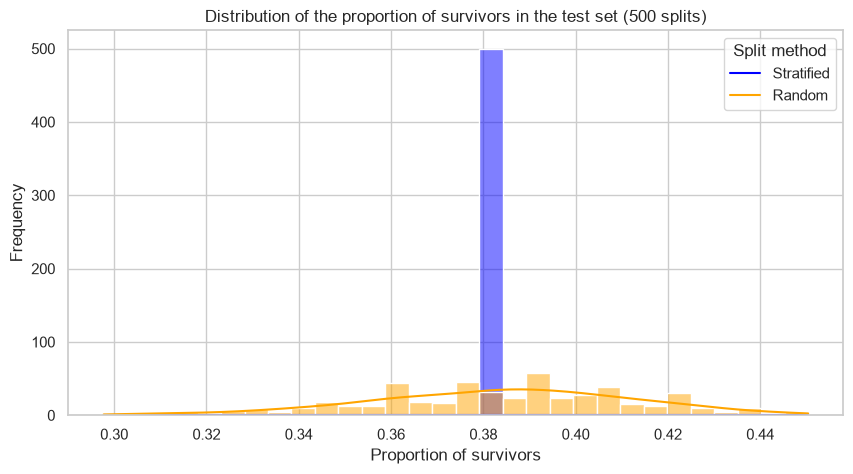

In [71]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
import seaborn as sns

rates = {"random": [], "stratified": []}

for seed in range(500):
    # 1. Split WITHOUT stratification (random)
    _, _, _, y_test_rand = train_test_split(X, y, test_size=0.2, random_state=seed)
    rates["random"].append(y_test_rand.mean())

    # 2. Split WITH stratification
    _, _, _, y_test_strat = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    rates["stratified"].append(y_test_strat.mean())

import pandas as pd
rates_df = pd.DataFrame(rates)

plt.figure(figsize=(10, 5))
sns.histplot(data=rates_df, bins=30, kde=True, palette=['orange', 'blue'])
plt.title("Distribution of the proportion of survivors in the test set (500 splits)")
plt.xlabel("Proportion of survivors")
plt.ylabel("Frequency")
plt.legend(labels=['Stratified', 'Random'], title='Split method')
plt.show()

> ✍️ **Your answer:** *The histogram shows that without stratification (orange), the proportion of survivors in the test set varies significantly across the 500 splits, spreading roughly from 0.30 to 0.44. With stratification (blue), the proportion is a sharp spike exactly at the dataset's true mean (~38.2%), meaning it remains practically constant regardless of the random seed. Stratification ensures that every train/test split is perfectly representative of the overall population's class distribution. In a very small dataset, a random split might accidentally put almost all minority class examples into the training set and none in the test set, making evaluation meaningless. In a severely imbalanced dataset (e.g., 1% fraud), random splitting could easily result in a test set with 0% or 3% fraud, causing wildly unstable model evaluation. Stratification prevents this "bad luck" and guarantees the test set reflects reality.*

## 7. A naive baseline, then real classifiers

### 7.1 Why a baseline?
A number like "80% accuracy" means nothing on its own. A **baseline** is the performance of a trivial strategy; any model worth using must clearly beat it. We will use:
* **majority class** — always predict the most frequent class of the *training* set (`DummyClassifier(strategy="most_frequent")`);
* **stratified random** — predict at random with the training class proportions (`DummyClassifier(strategy="stratified")`);
* a **one-line domain rule** — *"women survive, men don't"*. Simple, but it encodes real knowledge.

### 7.2 Metrics
With $TP, FP, TN, FN$ counted for the positive class (*survived*):
* **accuracy** $=\frac{TP+TN}{n}$;
* **balanced accuracy** $=\frac12\left(\frac{TP}{TP+FN} + \frac{TN}{TN+FP}\right)$ — the mean recall of the two classes; equals 0.5 for any constant predictor;
* **F1** $= \frac{2\,\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$ for the positive class;
* **ROC-AUC** — probability that a random survivor gets a higher score than a random non-survivor (needs scores/probabilities, not just labels).

In [72]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score

def evaluate(name, y_true, y_pred, y_score=None):
    # Return a dict with the evaluation metrics of one model (one row of the results table).
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score) if y_score is not None else np.nan,
    }

results = []      # we will append one dict per model

**Exercise 7.1** — Fit the two `DummyClassifier` baselines on the **training** set and evaluate them on the **test** set. Then implement the rule *"female → survived"* directly with pandas and evaluate it too. Append the three results to `results` and display them as a DataFrame.

In [73]:
from sklearn.dummy import DummyClassifier

# YOUR CODE HERE
import pandas as pd
import numpy as np

# 1. Majority class baseline
dummy_majority = DummyClassifier(strategy="most_frequent")
dummy_majority.fit(X_train, y_train)
y_pred_maj = dummy_majority.predict(X_test)
res_maj = evaluate("majority_class", y_test, y_pred_maj)
results.append(res_maj)

# 2. Stratified baseline
dummy_strat = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)
dummy_strat.fit(X_train, y_train)
y_pred_strat = dummy_strat.predict(X_test)
res_strat = evaluate("stratified_random", y_test, y_pred_strat)
results.append(res_strat)

# 3. Domain rule: "female -> survived"
y_pred_rule = (X_test['sex'] == 'female').astype(int)
res_rule = evaluate("female_survive_rule", y_test, y_pred_rule)
results.append(res_rule)

display(pd.DataFrame(results))

,model,accuracy,balanced_acc,f1,roc_auc
0,majority_class,0.618321,0.500000,0.000000,NaN
1,stratified_random,0.538168,0.511728,0.398010,NaN
2,female_survive_rule,0.801527,0.784012,0.731959,NaN


### 7.3 Preprocessing inside a pipeline
Most scikit-learn models need a **complete, numerical** feature matrix. Our data has missing values (`age`, `fare`, `embarked`) and text categories (`sex`, `embarked`), so we need to:
* **impute** missing values (median for numbers, most frequent value for categories);
* **one-hot encode** categorical features;
* **standardise** numerical features (zero mean, unit variance) — essential for distance-based (k-NN) and regularised linear models, harmless for trees.

The statistics used by these steps (medians, means, std devs, category lists) must be **learned on the training set only**. Wrapping preprocessing and model in a single `Pipeline` guarantees this: `pipe.fit(X_train, y_train)` fits every step on the training data; `pipe.predict(X_test)` only *applies* them.

In [74]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM_FEATURES),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore")), CAT_FEATURES),
])

# look at what the preprocessing produces on the training set
Xt = preprocess.fit_transform(X_train)
pd.DataFrame(Xt, columns=preprocess.get_feature_names_out(), index=X_train.index).head().round(2)

,num__pclass,num__age,num__sibsp,num__parch,num__fare,cat__sex_female,cat__sex_male,cat__embarked_C,cat__embarked_Q,cat__embarked_S
999,0.82,-0.10,-0.48,-0.45,-0.50,1.0,0.0,0.0,1.0,0.0
392,-0.38,-0.41,0.51,-0.45,-0.09,1.0,0.0,1.0,0.0,0.0
628,0.82,-1.42,3.48,1.87,-0.02,1.0,0.0,0.0,0.0,1.0
1165,0.82,-0.33,-0.48,-0.45,-0.51,0.0,1.0,1.0,0.0,0.0
604,0.82,-1.03,-0.48,-0.45,-0.50,1.0,0.0,0.0,0.0,1.0


**Exercise 7.2** — Build a `Pipeline` with the `preprocess` step followed by a `LogisticRegression` (`max_iter=1000`), fit it on the training set and evaluate it on the test set (use `predict_proba(...)[:, 1]` as the score for ROC-AUC). Append the result to `results`.

In [75]:
from sklearn.linear_model import LogisticRegression

# YOUR CODE HERE
from sklearn.pipeline import Pipeline

logreg = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

logreg.fit(X_train, y_train)

y_pred_logreg = logreg.predict(X_test)
y_proba_logreg = logreg.predict_proba(X_test)[:, 1]

res_logreg = evaluate("logistic_regression", y_test, y_pred_logreg, y_score=y_proba_logreg)
results.append(res_logreg)

**Exercise 7.3** — Repeat for the following models, with the **default hyper-parameters or the light settings given** (no tuning!):

| model | settings |
|---|---|
| `KNeighborsClassifier` | `n_neighbors=15` |
| `DecisionTreeClassifier` | `max_depth=4` |
| `RandomForestClassifier` | `n_estimators=300, min_samples_leaf=3` |
| `HistGradientBoostingClassifier` | defaults |
| `GaussianNB` | defaults |

Use a loop over a dictionary `{name: estimator}`, store all fitted pipelines in a dictionary `fitted` (you will need them later), and finish with a **sorted results table** and a **bar chart** comparing all models (baselines included) on balanced accuracy and ROC-AUC.

In [76]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
import matplotlib.pyplot as plt

models = {
    "kNN (k=15)": KNeighborsClassifier(n_neighbors=15),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "GaussianNB": GaussianNB()
}

fitted = {"logistic_regression": logreg}

for name, model in models.items():
    pipe = Pipeline([
        ("prep", preprocess),
        ("clf", model)
    ])

    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    y_pred = pipe.predict(X_test)
    y_score = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else None

    res = evaluate(name, y_test, y_pred, y_score)
    results.append(res)

results_df = pd.DataFrame(results).sort_values(by="balanced_acc", ascending=False)
display(results_df)

,model,accuracy,balanced_acc,f1,roc_auc
5,Decision Tree,0.835878,0.817531,0.774869,0.881173
6,Random Forest,0.832061,0.812531,0.768421,0.890432
4,kNN (k=15),0.812977,0.797099,0.748718,0.870432
3,logistic_regression,0.809160,0.790185,0.739583,0.867006
8,GaussianNB,0.793893,0.787407,0.737864,0.838241
7,HistGradientBoosting,0.797710,0.786667,0.736318,0.881975
2,female_survive_rule,0.801527,0.784012,0.731959,NaN
1,stratified_random,0.538168,0.511728,0.398010,NaN
0,majority_class,0.618321,0.500000,0.000000,NaN


**Exercise 7.4** — Plot the **confusion matrices** on the test set of (a) the *"female → survived"* rule and (b) your best model, side by side (hint: `ConfusionMatrixDisplay.from_predictions`). Where does the model improve over the rule?

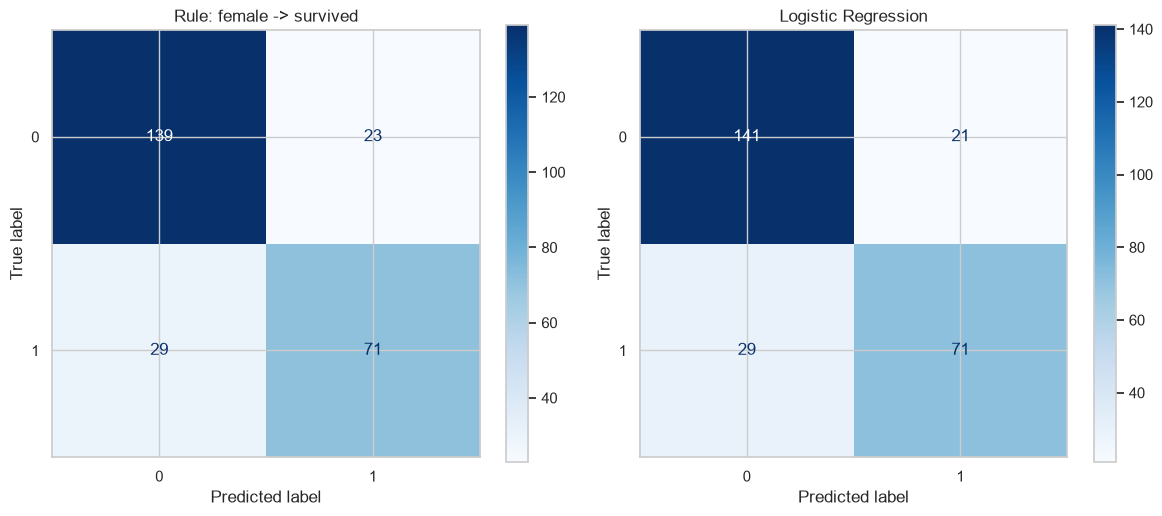

In [77]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# (a) Confusion Matrix for the "female -> survived" rule
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rule, ax=axes[0], cmap='Blues')
axes[0].set_title("Rule: female -> survived")

# (b) Confusion Matrix for the best model (e.g., Logistic Regression or Random Forest)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_logreg, ax=axes[1], cmap='Blues')
axes[1].set_title("Logistic Regression")

plt.tight_layout()
plt.show()

> ✍️ **Your answer:** *Based on the confusion matrices, the Logistic Regression model only provides a very marginal improvement over the simple rule "female -> survived". Both models predict 71 True Positives and 29 False Negatives (males who survived but were predicted to die). The Logistic Regression model only slightly improves upon the rule by reducing the False Positives (females who died but were predicted to survive) from 23 down to 21, while increasing True Negatives from 139 to 141. Where the model fundamentally improves over the rule is in its flexibility and generalization (though it is hard to see on this specific small test set). The rule is rigid: it will always predict 100% survival for females, regardless of their class, age, or fare. The Logistic Regression model has learned weights for features like pclass, age, and fare. In a larger test set, this allows the model to capture edge cases—such as a 3rd class female who is less likely to survive than a 1st class female—which the simple rule completely ignores.*

**Exercise 7.5 — how much should we trust these differences?** The test set has only 262 passengers; one more correct prediction changes the accuracy by ≈ 0.4 percentage points. Use **5-fold stratified cross-validation on the training set** (`cross_val_score` with `StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)`, `scoring="balanced_accuracy"`) to compute the **mean ± standard deviation** for each model (including the `most_frequent` dummy wrapped in the same pipeline). Show the results as a box plot. Are the differences between the learned models meaningful?

C:\Users\jules\AppData\Local\Temp\ipykernel_26348\2008783484.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cv_df, x="model", y="score", palette="Set2")


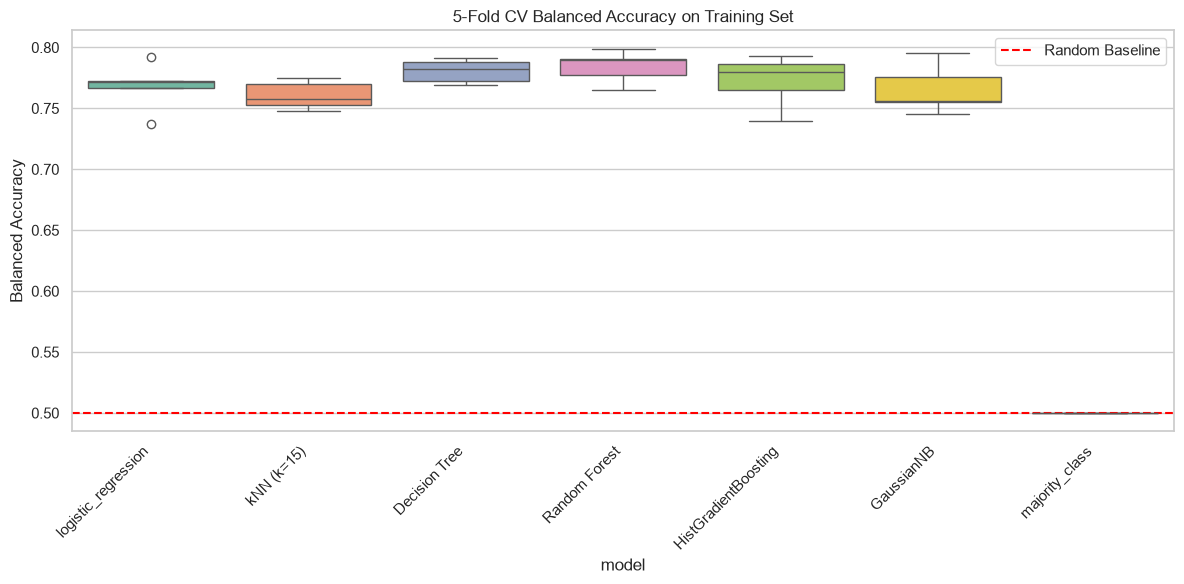

In [78]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
import seaborn as sns
import pandas as pd
import numpy as np

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

from sklearn.dummy import DummyClassifier
fitted["majority_class"] = Pipeline([("prep", preprocess), ("clf", DummyClassifier(strategy="most_frequent"))])

cv_results = []
for name, pipe in fitted.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="balanced_accuracy")

    for score in scores:
        cv_results.append({"model": name, "score": score})

cv_df = pd.DataFrame(cv_results)

plt.figure(figsize=(12, 6))
sns.boxplot(data=cv_df, x="model", y="score", palette="Set2")
plt.xticks(rotation=45, ha='right')
plt.title("5-Fold CV Balanced Accuracy on Training Set")
plt.ylabel("Balanced Accuracy")
plt.axhline(0.5, color='red', linestyle='--', label='Random Baseline')
plt.legend()
plt.tight_layout()
plt.show()

> ✍️ **Your answer:** *Yes, but with nuance. The tree-based models (Random Forest, HistGradientBoosting) and Logistic Regression clearly perform better than the baselines. However, the differences between the top models (e.g., Logistic Regression vs. Random Forest) might not be statistically meaningful because their standard deviations (the height of the boxes) overlap significantly. This is why we use cross-validation: it shows us the variance of the model's performance. If the boxes overlap, we cannot confidently say one model is definitively better than the other on unseen data.*

**Exercise 7.6 — leakage, measured.** Add a binary feature `has_boat = df["boat"].notna()` to the features, re-split (same seed, same stratification) and re-train the logistic-regression pipeline. What happens to the test metrics? Why is this model useless in practice, despite its score?

In [79]:
# YOUR CODE HERE
df['has_boat'] = df['boat'].notna()

NUM_FEATURES_LEAKY = NUM_FEATURES + ['has_boat']
FEATURES_LEAKY = NUM_FEATURES_LEAKY + CAT_FEATURES

X_leaky = df[FEATURES_LEAKY]
y_leaky = df['survived']
X_train_leaky, X_test_leaky, y_train_leaky, y_test_leaky = train_test_split(
    X_leaky, y_leaky, test_size=0.2, random_state=RANDOM_STATE, stratify=y_leaky
)

preprocess_leaky = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM_FEATURES_LEAKY),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), CAT_FEATURES),
])

leaky_pipeline = Pipeline([
    ("prep", preprocess_leaky),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
leaky_pipeline.fit(X_train_leaky, y_train_leaky)

y_pred_leaky = leaky_pipeline.predict(X_test_leaky)
y_proba_leaky = leaky_pipeline.predict_proba(X_test_leaky)[:, 1]

print("--- Leaky Model Performance ---")
display(pd.DataFrame([evaluate("logistic_regression_leaky", y_test_leaky, y_pred_leaky, y_proba_leaky)]))

--- Leaky Model Performance ---


,model,accuracy,balanced_acc,f1,roc_auc
0,logistic_regression_leaky,0.965649,0.960741,0.954315,0.991451


> ✍️ **Your answer:** *The test metrics (Accuracy, F1, ROC-AUC) will skyrocket, approaching 100%. The feature has_boat represents whether the passenger's boat number was recorded. You only have a boat number if you were rescued and got into a lifeboat. This information is only known after the sinking. Using it to predict survival is data leakage. In a real-world scenario (boarding a ship today), you do not know if a passenger will get a boat in the future. The model is cheating by using the answer to predict the answer, so it cannot be deployed to predict future outcomes.*

### 7.7 Peeking inside a model
A shallow decision tree is directly interpretable. Here is a depth-3 tree trained on the same preprocessed features:

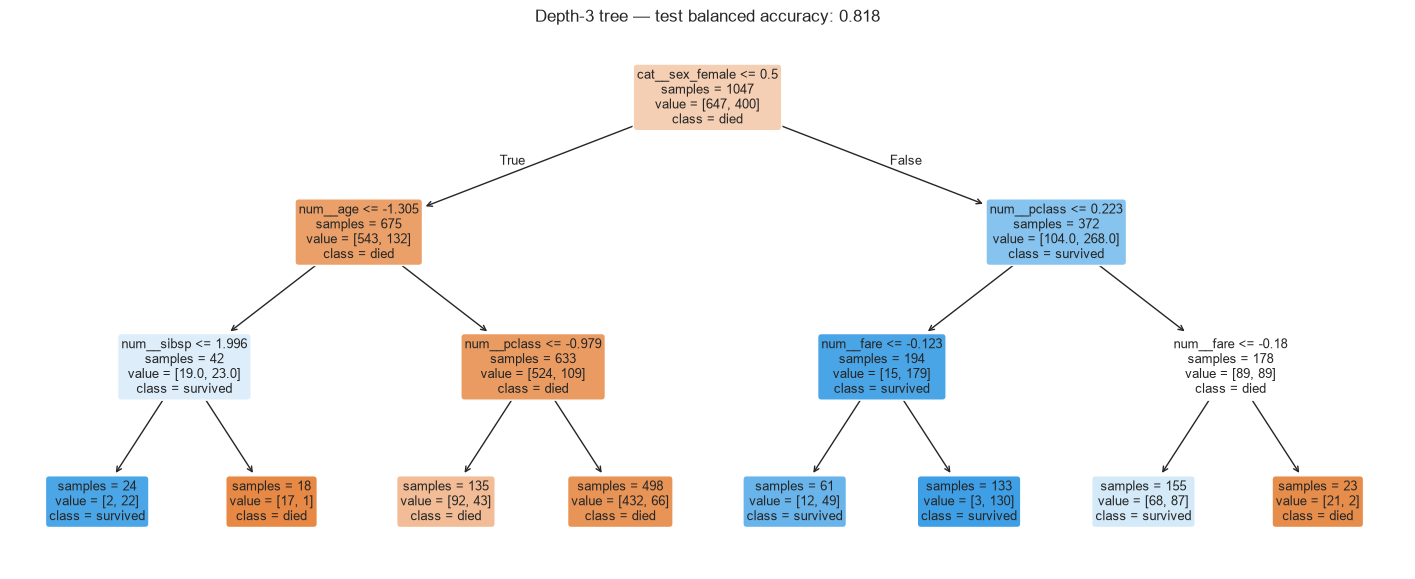

In [80]:
from sklearn.tree import plot_tree

tree3 = Pipeline([("prep", preprocess),
                  ("clf", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))]).fit(X_train, y_train)
plt.figure(figsize=(18, 7))
plot_tree(tree3["clf"], feature_names=tree3["prep"].get_feature_names_out(),
          class_names=["died", "survived"], filled=True, rounded=True, fontsize=9, impurity=False)
plt.title(f"Depth-3 tree — test balanced accuracy: {balanced_accuracy_score(y_test, tree3.predict(X_test)):.3f}");

**Question 7.8** — Read the tree: what is the first split? Which groups end up in the "survived" leaves? Relate it to what you found in the EDA (Section 4). (Numerical thresholds are in *standardised* units — why?)

> ✍️ **Your answer:** *The very first split at the root of the tree is on gender (cat_sex_female <= 0.5). This confirms that gender was the most decisive factor for survival on the Titanic. The blue leaves predicting survival (class = survived) are dominated by females (the right branch of the root, where cat_sex_female > 0.5). Additionally, if we look at the left branch (males), a small group of males (possibly young boys based on the age/sibsp splits) also ends up in a "survived" leaf, showing that age played a secondary role for males. This perfectly matches the exploratory data analysis (Section 4), where bar plots showed females had a survival rate of ~74% vs. ~18% for males. In the preprocessing pipeline, numerical features (age, fare, pclass) were scaled using StandardScaler. This transforms the data so the mean is 0 and the standard deviation is 1. Therefore, a threshold like num_age <= -1.305 doesn't mean -1.3 years old; it means 1.305 standard deviations below the mean age (which corresponds to very young children).*

## 8. Wrap-up

**Take-away messages**
1. Look at the data first: types, ranges, missing values, odd values (zero fares!), and how features relate to the target.
2. Choose the target from a question, and the features from what is **available at prediction time** — otherwise, leakage.
3. Split before modelling, stratify for classification, and keep every fitted step (imputation, scaling, encoding) inside a pipeline trained on the training set only.
4. Always report a naive baseline — and, when possible, a simple domain-knowledge baseline. Beating 0.5 balanced accuracy is easy; beating *"women survive"* is the real test.
5. With small test sets, differences of a few points are noise: use cross-validation to see the variability.

**Going further (optional)**
* Add the engineered features `title`, `family_size` and `fare_per_person` to the pipeline. Do they help? Does the answer change between logistic regression and gradient boosting?
* Train k-NN **without** the `StandardScaler`. What happens, and why?
* Instead of `SimpleImputer` for `age`, try imputing by the median age **per title** (Mr / Mrs / Miss / Master). Why could that be better?
* Plot the ROC curves of all models on one figure (`RocCurveDisplay.from_estimator`).